# Execução isolada do TC3-38

Este notebook apresenta isoladamente a etapa de auditoria da Feature Table `ml_aluno`. O desenvolvimento analítico abaixo é uma cópia fiel do bloco TC3-38 do notebook principal.

A única adição é a inicialização independente necessária para executar a etapa em um kernel limpo, no ambiente local ou no Docker.


In [1]:
# Inicialização independente: não altera a lógica canônica do TC3-38.
from pathlib import Path

import polars as pl
from IPython.display import display


def encontrar_raiz_projeto():
    atual = Path.cwd().resolve()
    candidatos = [atual, *atual.parents]
    for candidato in candidatos:
        entrada = candidato / 'dados' / 'fontes_originais' / 'principal' / 'ml_aluno.zip'
        if entrada.is_file():
            return candidato
    raise FileNotFoundError(
        'Não foi possível localizar dados/fontes_originais/principal/ml_aluno.zip. '
        'Execute o notebook dentro do repositório e confirme as fontes originais.'
    )


PROJECT_ROOT = encontrar_raiz_projeto()
FONTES_ORIGINAIS_DIR = PROJECT_ROOT / 'dados' / 'fontes_originais'
DADOS_PROCESSADOS_DIR = PROJECT_ROOT / 'dados' / 'dados_processados'
RESULTADOS_FIGURAS_DIR = PROJECT_ROOT / 'resultados' / 'figuras'


def salvar_figura_eda(figura, nome):
    destino_figura = RESULTADOS_FIGURAS_DIR / 'fluxo_exploratorio' / nome
    destino_figura.parent.mkdir(parents=True, exist_ok=True)
    figura.savefig(destino_figura, dpi=180, bbox_inches='tight')
    return destino_figura


print('Raiz do projeto:', PROJECT_ROOT)
print('Fonte principal:', FONTES_ORIGINAIS_DIR / 'principal' / 'ml_aluno.zip')


Raiz do projeto: /workspace
Fonte principal: /workspace/dados/fontes_originais/principal/ml_aluno.zip


# TC3-38 – Auditoria da Feature Table ml_aluno

**Responsável:** Sonia Andreia Ribeiro

**Sprint:** Fase 2

**Jira:** TC3-38, TC3-39

## Objetivo

Validar a qualidade da Feature Table `ml_aluno`, verificando sua integridade, estrutura e consistência antes da utilização nos modelos de Machine Learning.


In [2]:
import matplotlib.pyplot as plt
from pathlib import Path

# Configuração dos gráficos
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True


## 2. Configuração do ambiente

Nesta etapa definimos o caminho da Feature Table e localizamos automaticamente todos os arquivos Parquet das partições de 2023 e 2024.


In [3]:
import zipfile
from pathlib import Path

# A fonte compactada é somente leitura; sua extração é regenerável.
ZIP_PATH = FONTES_ORIGINAIS_DIR / "principal" / "ml_aluno.zip"
EXTRACT_PATH = DADOS_PROCESSADOS_DIR / "fontes_extraidas" / "principal"
EXTRACT_PATH.mkdir(parents=True, exist_ok=True)

if not (EXTRACT_PATH / "ml_aluno").exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

print("Arquivo zip:", ZIP_PATH)
print("Pasta de extração:", EXTRACT_PATH)


Arquivo zip: /workspace/dados/fontes_originais/principal/ml_aluno.zip
Pasta de extração: /workspace/dados/dados_processados/fontes_extraidas/principal


In [4]:
# Caminho local da feature table extraída
BASE_PATH = EXTRACT_PATH / "ml_aluno"

# Partições da Gold
PATH_2023 = BASE_PATH / "ano2023"
PATH_2024 = BASE_PATH / "ano2024"

print("2023:", PATH_2023)
print("2024:", PATH_2024)


2023: /workspace/dados/dados_processados/fontes_extraidas/principal/ml_aluno/ano2023
2024: /workspace/dados/dados_processados/fontes_extraidas/principal/ml_aluno/ano2024


In [5]:
for item in BASE_PATH.iterdir():
    print(item.name)


ano2023
ano2024


## 3. Localização dos arquivos Parquet

A Feature Table está particionada por ano. Vamos identificar automaticamente todos os arquivos disponíveis.


### 3.1 Conferência física e semântica das partições

Primeiro verificamos integridade física (quantidade e tamanho dos arquivos). Em seguida, comparamos cobertura e esquema. Nomes de arquivos Parquet são identificadores técnicos e **não** representam municípios, escolas ou alunos; portanto, diferenças entre esses nomes não caracterizam dados ausentes.


In [6]:
arquivos_2023 = sorted(PATH_2023.glob("*.parquet"))
arquivos_2024 = sorted(PATH_2024.glob("*.parquet"))
if not arquivos_2023 or not arquivos_2024:
    raise FileNotFoundError(
        "Partições anuais não encontradas. Verifique PATH_2023, PATH_2024 e a extração de ml_aluno.zip."
    )

auditoria_particoes_fisicas = pl.DataFrame({
    "ano_referencia": [2023, 2024],
    "arquivos_parquet": [len(arquivos_2023), len(arquivos_2024)],
    "tamanho_mb": [
        round(sum(arq.stat().st_size for arq in arquivos_2023) / (1024 ** 2), 2),
        round(sum(arq.stat().st_size for arq in arquivos_2024) / (1024 ** 2), 2),
    ],
})
display(auditoria_particoes_fisicas)
print("A quantidade de arquivos descreve apenas o particionamento físico; não mede cobertura de dados.")


ano_referencia,arquivos_parquet,tamanho_mb
i64,i64,f64
2023,36,50.42
2024,33,52.95


A quantidade de arquivos descreve apenas o particionamento físico; não mede cobertura de dados.


In [7]:
print("===== 2023 =====")
for arq in arquivos_2023:
    print(arq.name)

print("\n===== 2024 =====")
for arq in arquivos_2024:
    print(arq.name)


===== 2023 =====
part-00000-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00001-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00002-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00003-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00004-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00005-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00006-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00007-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00008-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00009-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00010-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00011-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00012-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00013-50211aad-067c-430c-b8fe-99a5652e1b40.c000.snappy.parquet
part-00014-50211aad-067c-430c-b

In [8]:
df_2023 = pl.concat(
    [pl.read_parquet(arq) for arq in arquivos_2023],
    how="vertical_relaxed",
    rechunk=False,
)
df_2024 = pl.concat(
    [pl.read_parquet(arq) for arq in arquivos_2024],
    how="vertical_relaxed",
    rechunk=False,
)
print(f"Partições carregadas — 2023: {df_2023.height:,} linhas | 2024: {df_2024.height:,} linhas")


Partições carregadas — 2023: 1,747,439 linhas | 2024: 2,120,560 linhas


## Auditoria anual — cobertura e compatibilidade

A comparação relevante ocorre sobre o conteúdo: registros, entidades distintas, colunas e tipos. Quantidades anuais diferentes são esperadas quando há mudança de cobertura; só passam a representar inconsistência quando violam o contrato da fonte ou a granularidade esperada.


In [9]:
def resumir_particao_anual(frame, ano):
    expressoes = [pl.len().alias("registros")]
    for coluna, alias in [
        ("id_aluno", "alunos_distintos"),
        ("id_escola", "escolas_distintas"),
        ("id_municipio", "municipios_distintos"),
    ]:
        if coluna in frame.columns:
            expressoes.append(pl.col(coluna).n_unique().alias(alias))
    resumo = frame.select(expressoes).with_columns(
        pl.lit(ano).alias("ano_referencia"),
        pl.lit(frame.width).alias("colunas"),
    )
    return resumo.select("ano_referencia", *[c for c in resumo.columns if c != "ano_referencia"])

auditoria_semantica_anual = pl.concat([
    resumir_particao_anual(df_2023, 2023),
    resumir_particao_anual(df_2024, 2024),
], how="vertical_relaxed")
display(auditoria_semantica_anual)


ano_referencia,registros,alunos_distintos,escolas_distintas,municipios_distintos,colunas
i32,u32,u32,u32,u32,i32
2023,1747439,1747439,36776,4873,19
2024,2120560,2120560,42497,5519,19


In [10]:
schema_2023 = {nome: str(tipo) for nome, tipo in df_2023.schema.items()}
schema_2024 = {nome: str(tipo) for nome, tipo in df_2024.schema.items()}
somente_2023 = sorted(set(schema_2023) - set(schema_2024))
somente_2024 = sorted(set(schema_2024) - set(schema_2023))
tipos_divergentes = sorted(
    nome for nome in set(schema_2023) & set(schema_2024)
    if schema_2023[nome] != schema_2024[nome]
)
auditoria_schema_anual = pl.DataFrame({
    "verificacao": ["colunas_somente_2023", "colunas_somente_2024", "tipos_divergentes"],
    "quantidade": [len(somente_2023), len(somente_2024), len(tipos_divergentes)],
    "detalhes": [", ".join(somente_2023), ", ".join(somente_2024), ", ".join(tipos_divergentes)],
})
display(auditoria_schema_anual)
assert not somente_2023 and not somente_2024, "As partições anuais possuem colunas diferentes."
assert not tipos_divergentes, "As partições anuais possuem tipos incompatíveis."


verificacao,quantidade,detalhes
str,i64,str
"""colunas_somente_2023""",0,""""""
"""colunas_somente_2024""",0,""""""
"""tipos_divergentes""",0,""""""


## 4. Consolidação da Feature Table

As partições anuais são unificadas para formar a Feature Table completa (`ml_aluno`), que será utilizada nas etapas de EDA, engenharia de features e modelagem.


In [11]:
df = pl.concat([df_2023, df_2024], how="vertical_relaxed", rechunk=True)
print("=" * 40)
print("FEATURE TABLE CONSOLIDADA")
print("=" * 40)
print(f"Registros: {df.height:,}")
print(f"Colunas: {df.width}")


FEATURE TABLE CONSOLIDADA
Registros: 3,867,999
Colunas: 19


## 5. Inventário da Feature Table

Resumo estrutural da base consolidada utilizada na modelagem de Machine Learning.


In [12]:
_schema_df = df.schema
_numericas = [c for c, t in _schema_df.items() if t.is_numeric()]
resumo = pl.DataFrame({
    "Métrica": ["Registros", "Colunas", "Variáveis numéricas", "Variáveis categóricas"],
    "Valor": [df.height, df.width, len(_numericas), df.width - len(_numericas)],
})
resumo


Métrica,Valor
str,i64
"""Registros""",3867999
"""Colunas""",19
"""Variáveis numéricas""",10
"""Variáveis categóricas""",9


## 6. Estrutura das variáveis

Validação dos tipos de dados, memória utilizada e consistência estrutural da Feature Table.


In [13]:
print("Informações estruturais")
print(f"Linhas: {df.height:,} | Colunas: {df.width:,}")
print(f"Memória estimada: {df.estimated_size('mb'):.2f} MB")
display(pl.DataFrame({"Variável": df.columns, "Tipo": [str(tipo) for tipo in df.dtypes]}))


Informações estruturais
Linhas: 3,867,999 | Colunas: 19
Memória estimada: 432.53 MB


Variável,Tipo
str,str
"""id_aluno""","""String"""
"""id_escola""","""String"""
"""id_municipio""","""String"""
"""nome_municipio""","""String"""
"""sigla_uf""","""String"""
…,…
"""taxa_alfabetizacao_municipio_a…","""Float64"""
"""media_portugues_municipio_ano_…","""Float64"""
"""dataset_split""","""String"""


In [14]:
dicionario = pl.DataFrame({
    "Variável": df.columns,
    "Tipo": [str(t) for t in df.dtypes],
    "Nulos": [df[c].null_count() for c in df.columns],
    "% Nulos": [round(100 * df[c].null_count() / df.height, 2) for c in df.columns],
    "Valores únicos": [df[c].n_unique() for c in df.columns],
}).sort("% Nulos", descending=True)
dicionario


Variável,Tipo,Nulos,% Nulos,Valores únicos
str,str,i64,f64,i64
"""taxa_alfabetizacao_municipio_a…","""Float64""",1791646,46.32,4062
"""media_portugues_municipio_ano_…","""Float64""",1791646,46.32,6402
"""proficiencia""","""Float64""",513338,13.27,1299545
"""peso_aluno""","""Float64""",513338,13.27,70529
"""id_aluno""","""String""",0,0.0,2352328
…,…,…,…,…
"""presenca""","""Int32""",0,0.0,2
"""preenchimento_caderno""","""Int32""",0,0.0,2
"""dataset_split""","""String""",0,0.0,3


## 6. Auditoria de valores nulos

Classificação das variáveis conforme o percentual de valores ausentes, identificando possíveis riscos para a modelagem.


In [15]:
nulos = dicionario.filter(pl.col("Nulos") > 0).sort("% Nulos", descending=True)
nulos


Variável,Tipo,Nulos,% Nulos,Valores únicos
str,str,i64,f64,i64
"""taxa_alfabetizacao_municipio_a…","""Float64""",1791646,46.32,4062
"""media_portugues_municipio_ano_…","""Float64""",1791646,46.32,6402
"""proficiencia""","""Float64""",513338,13.27,1299545
"""peso_aluno""","""Float64""",513338,13.27,70529


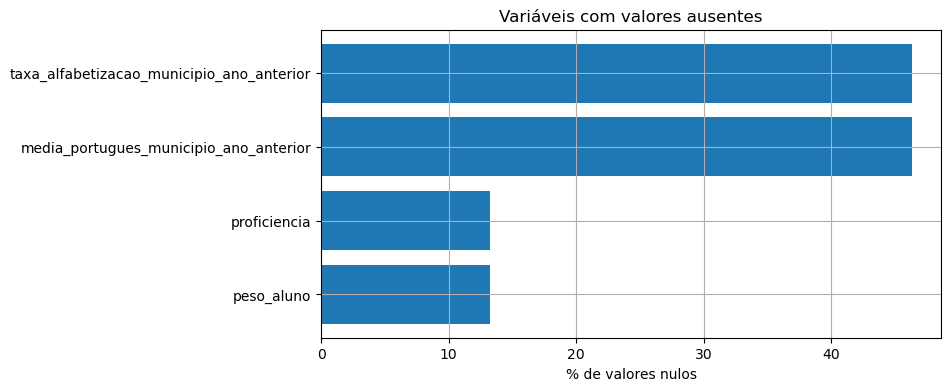

In [16]:
plt.figure(figsize=(8,4))

plt.barh(
    nulos["Variável"],
    nulos["% Nulos"]
)

plt.xlabel("% de valores nulos")
plt.title("Variáveis com valores ausentes")
plt.gca().invert_yaxis()

salvar_figura_eda(plt.gcf(), "032_6_auditoria_de_valores_nulos_01.png"); plt.show()


In [17]:
duplicados = df.height - df.select(pl.col("id_aluno").n_unique()).item()
print(f"IDs de aluno duplicados: {duplicados:,}")
print(f"Alunos únicos: {df['id_aluno'].n_unique():,}")


IDs de aluno duplicados: 1,515,671
Alunos únicos: 2,352,328


## 7. Validação da granularidade

Verificação da regra de negócio: uma linha representa um aluno ou uma observação do aluno?


In [18]:
ocorrencias = (
    df.group_by("id_aluno").len().rename({"len": "registros_por_aluno"})
    .group_by("registros_por_aluno").len()
    .rename({"registros_por_aluno": "Quantidade de registros por aluno", "len": "Número de alunos"})
    .sort("Quantidade de registros por aluno")
)
ocorrencias


Quantidade de registros por aluno,Número de alunos
u32,u32
1,836657
2,1515671


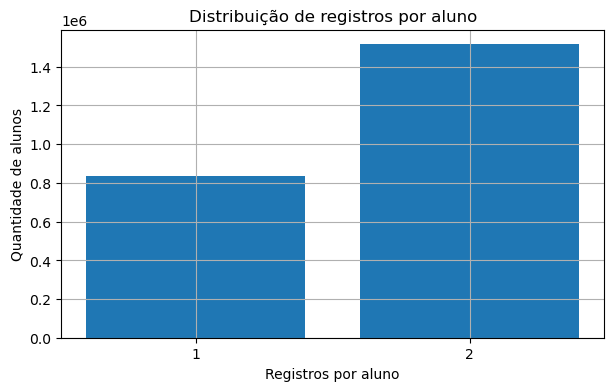

In [19]:
plt.figure(figsize=(7, 4))
plt.bar(
    ocorrencias["Quantidade de registros por aluno"].cast(pl.String).to_list(),
    ocorrencias["Número de alunos"].to_numpy(),
)
plt.title("Distribuição de registros por aluno")
plt.xlabel("Registros por aluno")
plt.ylabel("Quantidade de alunos")
salvar_figura_eda(plt.gcf(), "036_7_validacao_da_granularidade_01.png"); plt.show()


### Achado 04 — Granularidade da Feature Table

A validação da chave `id_aluno` demonstrou que a Feature Table possui natureza longitudinal.

**Conclusão:** a unidade analítica é uma observação anual do aluno, e não um registro único por aluno.


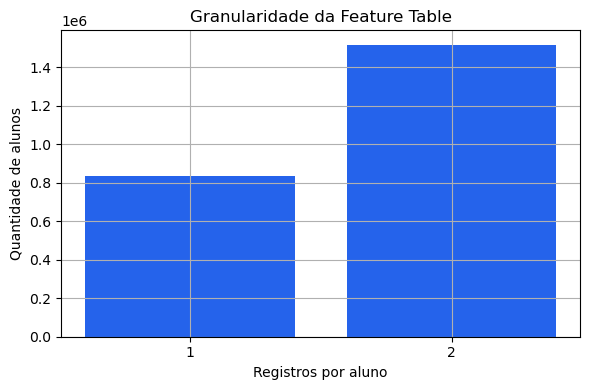

In [20]:
plt.figure(figsize=(6, 4))
plt.bar(
    ocorrencias["Quantidade de registros por aluno"].cast(pl.String).to_list(),
    ocorrencias["Número de alunos"].to_numpy(),
    color="#2563EB",
)
plt.title("Granularidade da Feature Table")
plt.xlabel("Registros por aluno")
plt.ylabel("Quantidade de alunos")
plt.xticks(rotation=0)
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "038_achado_04_granularidade_da_feature_table_01.png")
plt.show()


In [21]:
validacao = (
    df.group_by("id_aluno").agg(pl.col("ano_referencia").n_unique().alias("anos_distintos"))
    .group_by("anos_distintos").len().sort("anos_distintos")
)
validacao


anos_distintos,len
u32,u32
1,836657
2,1515671


### Achado 04 — Validação da Granularidade

A análise da chave `id_aluno` demonstrou que a Feature Table possui natureza longitudinal.

Dos **2.352.328 alunos únicos**, **1.515.671** possuem registros em dois anos de referência (2023 e 2024), enquanto **836.657** aparecem em apenas um ano.

**Conclusão:** a unidade analítica da `ml_aluno` é **1 linha = 1 aluno por ano de referência**, e não um registro único por aluno.


## 8. Distribuição da variável alvo

Validação do balanceamento da variável `alfabetizado`, identificando a proporção entre as classes positivas e negativas.


In [22]:
target = (
    df.group_by("alfabetizado", maintain_order=True).len().rename({"alfabetizado": "Classe", "len": "Quantidade"})
    .with_columns((100 * pl.col("Quantidade") / pl.col("Quantidade").sum()).round(2).alias("Percentual"))
    .sort("Classe")
)
target


Classe,Quantidade,Percentual
i32,u32,f64
0,1883453,48.69
1,1984546,51.31


### Distribuição da variável `alfabetizado`

Análise do balanceamento entre as classes da variável alvo.


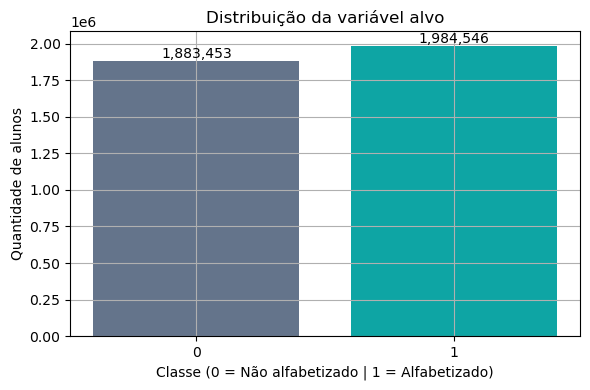

In [23]:
plt.figure(figsize=(6, 4))
classes = target["Classe"].cast(pl.String).to_list()
quantidades = target["Quantidade"].to_numpy()
plt.bar(classes, quantidades, color=["#64748B", "#0EA5A4"][:len(classes)])
plt.title("Distribuição da variável alvo")
plt.xlabel("Classe (0 = Não alfabetizado | 1 = Alfabetizado)")
plt.ylabel("Quantidade de alunos")
for i, valor in enumerate(quantidades):
    plt.text(i, valor + 20000, f"{int(valor):,}", ha="center")
plt.tight_layout(); salvar_figura_eda(plt.gcf(), "044_distribuicao_da_variavel_alfabetizado_01.png"); plt.show()


In [24]:
split = (
    df.group_by("dataset_split").len().rename({"dataset_split": "Conjunto", "len": "Quantidade"})
    .with_columns((100 * pl.col("Quantidade") / pl.col("Quantidade").sum()).round(2).alias("Percentual"))
    .sort("Conjunto")
)
split


Conjunto,Quantidade,Percentual
str,u32,f64
"""teste""",581596,15.04
"""treino""",2705252,69.94
"""validacao""",581151,15.02


### Achado 06 — Validação do Dataset Split

A Feature Table apresenta uma estratégia de particionamento consistente para modelagem supervisionada.

| Conjunto | Percentual |
|----------|-----------:|
| Treino | 69,94% |
| Validação | 15,02% |
| Teste | 15,04% |

**Conclusão:** a divisão encontra-se balanceada e adequada para treinamento, ajuste de hiperparâmetros e avaliação final do modelo.


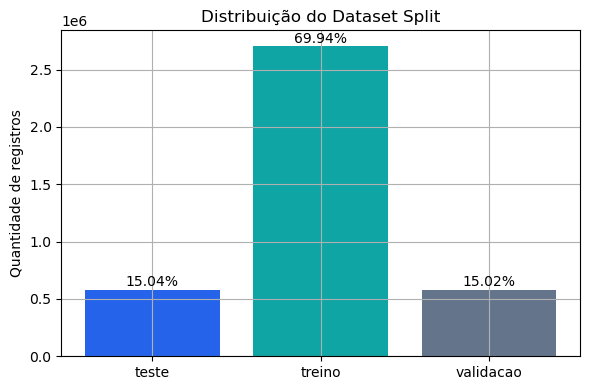

In [25]:
plt.figure(figsize=(6,4))

plt.bar(
    split["Conjunto"],
    split["Quantidade"],
    color=["#2563EB", "#0EA5A4", "#64748B"]
)

plt.title("Distribuição do Dataset Split")
plt.ylabel("Quantidade de registros")

for i, valor in enumerate(split["Quantidade"]):
    plt.text(i, valor + 30000, f"{split['Percentual'][i]}%", ha="center")

plt.tight_layout()
salvar_figura_eda(plt.gcf(), "047_achado_06_validacao_do_dataset_split_01.png"); plt.show()


## 9. Fontes complementares previstas para enriquecimento

A auditoria de integridade desta etapa continua concentrada na Feature Table `ml_aluno`. As fontes complementares abaixo foram identificadas no inventário do projeto e devem ser consideradas nas etapas posteriores; sua inclusão nesta seção **não significa que já foram integradas** à base principal.

- **Censo Escolar 2023 (INEP):** atributos de escola e infraestrutura. Arquivo previsto no repositório: `dados/fontes_originais/complementar/microdados_ed_basica_2023.zip`. Granularidade esperada: escola. Chaves candidatas: `CO_ENTIDADE` (escola), `CO_MUNICIPIO` (município) e `NU_ANO_CENSO` (ano).
- **INSE 2023 — escolas (INEP):** indicadores socioeconômicos no nível escolar. Arquivo: `dados/fontes_originais/complementar/INSE_2023_escolas.xlsx`. Granularidade: escola. Chaves candidatas: `ID_ESCOLA` e `CO_MUNICIPIO`; variáveis de interesse incluem `MEDIA_INSE`, `INSE_CLASSIFICACAO`, `PC_NIVEL_1` a `PC_NIVEL_10`, `TP_CAPITAL` e `QT_ALUNOS_INSE`.
- **IBGE Localidades:** as informações de identificação territorial já estão incorporadas à `ml_aluno`; não devem ser tratadas como uma nova fonte complementar nesta etapa.
- **Indicadores financeiros e socioeconômicos adicionais:** FUNDEB, Siconfi, PIB per capita e outros indicadores permanecem planejados e dependem de validação da fonte oficial, período, granularidade e chave de integração.

### Critérios para a integração futura

1. Confirmar a existência e o esquema dos arquivos locais antes de usá-los.
2. Validar a correspondência entre `id_escola` e os identificadores das fontes externas, além do ano de referência.
3. Verificar duplicidades nas chaves e a cobertura de escolas antes de qualquer junção.
4. Evitar multiplicação de linhas da `ml_aluno`: qualquer relacionamento deve preservar a granularidade aluno/ano esperada ou documentar explicitamente a regra de agregação.
5. Manter a auditoria atual separada da engenharia de features e da integração efetiva, que pertencem às etapas posteriores.


In [26]:
fontes_complementares = pl.DataFrame([
    {
        "Fonte": "Censo Escolar 2023 — INEP",
        "Arquivo previsto": "dados/fontes_originais/complementar/microdados_ed_basica_2023.zip",
        "Granularidade": "Escola",
        "Chaves candidatas": "CO_ENTIDADE; CO_MUNICIPIO; NU_ANO_CENSO",
        "Status nesta etapa": "Inventariada; integração não realizada"
    },
    {
        "Fonte": "INSE 2023 — escolas — INEP",
        "Arquivo previsto": "dados/fontes_originais/complementar/INSE_2023_escolas.xlsx",
        "Granularidade": "Escola",
        "Chaves candidatas": "ID_ESCOLA; CO_MUNICIPIO",
        "Status nesta etapa": "Inventariada; integração não realizada"
    },
    {
        "Fonte": "IBGE Localidades",
        "Arquivo previsto": "Já incorporada à ml_aluno",
        "Granularidade": "Territorial / conforme campos existentes",
        "Chaves candidatas": "id_municipio",
        "Status nesta etapa": "Não tratar como nova fonte"
    },
    {
        "Fonte": "FUNDEB / Siconfi / indicadores econômicos e sociais",
        "Arquivo previsto": "A definir após validação das fontes oficiais",
        "Granularidade": "A confirmar",
        "Chaves candidatas": "Município e ano, a confirmar",
        "Status nesta etapa": "Planejadas; ainda não validadas"
    }
])

fontes_complementares


Fonte,Arquivo previsto,Granularidade,Chaves candidatas,Status nesta etapa
str,str,str,str,str
"""Censo Escolar 2023 — INEP""","""dados/fontes_originais/complem…","""Escola""","""CO_ENTIDADE; CO_MUNICIPIO; NU_…","""Inventariada; integração não r…"
"""INSE 2023 — escolas — INEP""","""dados/fontes_originais/complem…","""Escola""","""ID_ESCOLA; CO_MUNICIPIO""","""Inventariada; integração não r…"
"""IBGE Localidades""","""Já incorporada à ml_aluno""","""Territorial / conforme campos …","""id_municipio""","""Não tratar como nova fonte"""
"""FUNDEB / Siconfi / indicadores…","""A definir após validação das f…","""A confirmar""","""Município e ano, a confirmar""","""Planejadas; ainda não validada…"


# 10. Parecer Técnico da Auditoria

## Status da Feature Table

🟢 **APTA PARA MODELAGEM**

### Principais evidências

- A Feature Table consolidada possui **3.867.999 registros** e **19 variáveis**.
- A granularidade foi validada como **1 linha = 1 aluno por ano de referência**.
- A variável alvo `alfabetizado` encontra-se balanceada (48,69% × 51,31%).
- O `dataset_split` apresenta distribuição adequada (70% / 15% / 15%).
- Foram identificadas quatro variáveis com valores ausentes, que deverão ser avaliadas na etapa de pré-processamento (TC3-49).

### Próximas etapas

- TC3-40 — Inventário e análise das variáveis.
- TC3-41 — Definição das features.
- TC3-49 — Estratégia de tratamento de nulos e engenharia de atributos.

**Referência ao TC3-39:** a análise da variável-alvo alfabetizado e do dataset_split, originalmente prevista nesta tarefa, está contemplada neste notebook, em conjunto com a auditoria da base ml_aluno.

**Limite de escopo:** o status da auditoria refere-se somente às verificações executadas sobre `ml_aluno`. Censo Escolar e INSE estão documentados como fontes complementares para etapas posteriores; ainda não foram integrados nem validados por junção neste notebook. A conclusão de aptidão deve ser interpretada à luz dos achados e das limitações registrados acima.
